# Entrenamiento y validación v12: p discretizadas + topología conjunta

Entrena el modelo con `datos_modelo.parquet` y lo valida con **topología real** (techo de la parte de p) y con **inferencia realista** (topología predicha), con las mismas métricas del notebook de referencia.

**Diferencia clave respecto al notebook de referencia:** el parquet no trae todas las columnas que el modelo necesita como entrada. La sección 3 las completa igual que lo hace producción (catálogos Tekla del `adapter`):

| falta en el parquet | se completa con |
|---|---|
| `BEAM_b_mm`, `BEAM_tf_mm`, `BEAM_tw_mm` | catálogo Tekla (`adapter._profile_lookup`) por nombre de perfil |
| `COLUMN_b_mm`, `COLUMN_tf_mm`, `COLUMN_tw_mm` | ídem |
| `Normativas` | se copia de `standard` (ver nota en la sección 3) |

**Estructura esperada del proyecto**

```
proyecto/
├── core/            # adapter.py config.py dataset.py evaluation.py losses.py model.py postprocess.py training.py (+ __init__.py)
├── data/
│   ├── datos_modelo.parquet
│   └── tekla_eu.csv  tekla_cad.csv  tekla_faltante.csv  tekla_uk.csv   # los lee adapter.DATA_DIR
└── este_notebook.ipynb
```

> `adapter.DATA_DIR` = carpeta `data/` junto a `core/`. Si tus CSV de Tekla están en otro sitio, cambia `adapter.DATA_DIR` en la sección 3.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import copy
import random
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupShuffleSplit, train_test_split

from core import adapter
from core.config import *
from core.dataset import (
    Preprocessor,
    ConnectionDataset,
    validate_connection_targets,
    validate_transition_labels,
)
from core.model import ConnectionDesignNet, ConnectionDesignNetV4, n_bins_from_train, p_confidence
from core.losses import ConnectionDesignLoss, ConnectionDesignLossV4
from core.training import fit, predict_loader
from core.evaluation import (
    preparar_para_evaluar,
    evaluar_predicciones,
    evaluar_estructura,
    evaluar_sesgo_p,
    evaluar_acumulado_y,
    evaluar_por_transicion,
    resumen_p,
    contribucion_error_topologia,
    calibracion_confianza_p,
)

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)

## 1. Configuración

| clave de `CFG` | valores | efecto |
|---|---|---|
| `model` | `"v3"` / `"v4"` | v3 = regresión de p; v4 = p discretizada en bins de 5 mm |
| `joint_topology` | `True` / `False` | solo v4: una softmax conjunta sobre (n_alma, n_cantonera) |
| `class_weights` | `True` / `False` | pesos inversos a la frecuencia en los conteos |
| `select_metric` | `"val_loss"`, `"p_and_topology"`, `"p_within_10"`, `"p_mae_mm"`, `"topology_exact"` | criterio para elegir la mejor época (validación realista) |
| `w_p_ce`, `label_scale_bins` | números | peso de la cross-entropy de p y suavizado ordinal de la etiqueta (solo v4) |

In [3]:
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_PATH = Path("data/datos_modelo.parquet")
OUTPUT_DIR = Path("artifacts_v4")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = OUTPUT_DIR / "best_v4.pt"

BATCH_SIZE = 128
EPOCHS = 200
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0

HIDDEN_DIM = 192
NUM_BLOCKS = 3
DROPOUT = 0.10
GRU_HIDDEN_DIM = 128

DEFAULT_CFG = dict(
    model="v12",
    joint_topology=True,
    class_weights=False,
    select_metric="p_and_topology",
    w_p_ce=2.0,
    label_scale_bins=1.0,
)
CFG = {**DEFAULT_CFG}          # <- edita aqui el experimento principal

# --- Completado de columnas que faltan en el parquet ---
NORMATIVAS_FROM = "standard"   # de que columna sale `Normativas` si no existe
UNKNOWN_PROFILES = "drop"      # "drop": descarta filas con perfil fuera del catalogo | "error": para
# --- Particion ---
#   "inputs": agrupa filas con entradas identicas (evita fuga por duplicados)
#   "UNICODE": agrupa por UNICODE (en este parquet es unico por fila => equivale a aleatorio)
#   None: particion aleatoria simple
SPLIT_GROUP = "inputs"

RUN_DIAGNOSTICS = True         # cierre geometrico, multimodalidad, duplicados (necesita core/diagnostico_p.py)
RUN_ABLATION = False           # seccion 18 (lenta: 5 configuraciones x semillas)
ABLATION_SEEDS = [0, 1, 2]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Dispositivo:", DEVICE)
print("Experimento :", CFG)

Dispositivo: cpu
Experimento : {'model': 'v12', 'joint_topology': True, 'class_weights': False, 'select_metric': 'p_and_topology', 'w_p_ce': 2.0, 'label_scale_bins': 1.0}


## 2. Carga del parquet

In [4]:
suffix = DATA_PATH.suffix.lower()
if suffix == ".parquet":
    df = pd.read_parquet(DATA_PATH)
elif suffix == ".csv":
    df = pd.read_csv(DATA_PATH)
elif suffix in {".xlsx", ".xls"}:
    df = pd.read_excel(DATA_PATH)
else:
    raise ValueError(f"Formato no soportado: {suffix}")

df = df.reset_index(drop=True)
print("Dimensiones:", df.shape)

faltan_entrada = [c for c in CATEGORICAL_FEATURES + NUMERIC_FEATURES if c not in df.columns]
print("Columnas de entrada del modelo que NO estan en el parquet:", faltan_entrada)

Dimensiones: (4671, 56)
Columnas de entrada del modelo que NO estan en el parquet: ['Normativas', 'BEAM_b_mm', 'BEAM_tf_mm', 'BEAM_tw_mm', 'COLUMN_b_mm', 'COLUMN_tf_mm', 'COLUMN_tw_mm']


## 3. Completar medidas de perfil y `Normativas`

Se reutiliza el catálogo de perfiles del `adapter` (`_profile_lookup`, indexado por nombre en mayúsculas y sin espacios), que es lo que usa producción. Así entrenamiento e inferencia ven exactamente las mismas medidas.

Notas:

- `adapter._add_profiles` solo rellena `*_type` y `*_d_mm`, aunque define `measures = ["d_mm", "b_mm", "tf_mm", "tw_mm"]`. Aquí se rellenan las cuatro medidas. **Producción necesita el mismo cambio**: `preprocess()` selecciona `FEATURE_COLUMNS` (que incluye `BEAM_b_mm`, `BEAM_tf_mm`, …) y fallará con `KeyError` porque esas columnas no se crean.
- Se comprueba que el `d_mm` del catálogo coincide con el del parquet (si no, los datos y el catálogo no son de la misma fuente).
- Se comprueba que `fy/fu` de acero y tornillo coinciden con `ACERO_TABLE` / `TORNILLO_TABLE`.
- **`Normativas`**: se copia de `standard`. El adapter ofrece como opciones de `Normativas` las clases de `standard`, y `standard` es a su vez una salida: el modelo aprenderá que `standard ≈ Normativas` (es lo esperado en producción, pero ese acierto no mide nada).

In [5]:
PROFILE_MEASURES = ["d_mm", "b_mm", "tf_mm", "tw_mm"]


def completar_perfiles(df, on_unknown="drop"):
    lookup = adapter._profile_lookup()
    faltan = [m for m in PROFILE_MEASURES if m not in lookup.columns]
    if faltan:
        raise KeyError(f"El catalogo Tekla no tiene las columnas {faltan}. Disponibles: {list(lookup.columns)}")

    df = df.copy()
    keep = np.ones(len(df), dtype=bool)
    for col in ("BEAM", "COLUMN"):
        keys = df[col].astype(str).str.strip().str.upper()
        known = keys.isin(lookup.index).to_numpy()
        if not known.all():
            unk = sorted(set(df.loc[~known, col].astype(str)))
            msg = f"{col}: {int((~known).sum())} filas con perfiles fuera del catalogo Tekla: {unk}"
            if on_unknown == "error":
                raise adapter.InputContractError(msg)
            print("AVISO ->", msg)
            keep &= known
        geom = lookup.reindex(keys)
        for m in PROFILE_MEASURES:
            new = pd.to_numeric(geom[m].to_numpy(), errors="coerce")
            if m == "d_mm" and f"{col}_d_mm" in df.columns:
                diff = np.abs(new - df[f"{col}_d_mm"].to_numpy(float))
                bad = np.nansum(diff > 1.0)
                print(f"{col}_d_mm: filas donde catalogo y parquet difieren > 1 mm: {int(bad)}")
                continue          # se conserva el d_mm del parquet
            df[f"{col}_{m}"] = new
    n0 = len(df)
    df = df.loc[keep].reset_index(drop=True)
    if n0 != len(df):
        print(f"Filas descartadas por perfil desconocido: {n0 - len(df)}")
    return df


if not adapter.DATA_DIR.exists():
    raise FileNotFoundError(f"No encuentro los catalogos Tekla en {adapter.DATA_DIR}. Ajusta adapter.DATA_DIR.")

df = completar_perfiles(df, on_unknown=UNKNOWN_PROFILES)

if "Normativas" not in df.columns:
    df["Normativas"] = df[NORMATIVAS_FROM].astype(str).str.strip()
    print(f"Normativas creada a partir de '{NORMATIVAS_FROM}':", df["Normativas"].value_counts().to_dict())

# Consistencia de materiales con las tablas del adapter
for col, table in (("grado_acero", adapter.ACERO_TABLE), ("clase_tornillo", adapter.TORNILLO_TABLE)):
    for prop in next(iter(table.values())):
        esperado = df[col].astype(str).str.strip().map(lambda v: table[v][prop])
        n_bad = int(((df[prop] - esperado).abs() > 1e-6).sum())
        print(f"{col} -> {prop}: filas inconsistentes con la tabla = {n_bad}")

nuevas = [c for c in NUMERIC_FEATURES if c.endswith(("_b_mm", "_tf_mm", "_tw_mm"))]
print("\nNulos en medidas nuevas:", df[nuevas].isna().sum().to_dict())
display(df[["BEAM", "COLUMN"] + nuevas].drop_duplicates().head(8))
display(df[nuevas].describe().T.round(1))

BEAM_d_mm: filas donde catalogo y parquet difieren > 1 mm: 0
COLUMN_d_mm: filas donde catalogo y parquet difieren > 1 mm: 0
Normativas creada a partir de 'standard': {'EN 1993-1-8': 2585, 'AISC-360-05/10': 1805, 'CSA S16-09': 281}
grado_acero -> fy_acero_mpa: filas inconsistentes con la tabla = 0
grado_acero -> fu_acero_mpa: filas inconsistentes con la tabla = 0
clase_tornillo -> fy_tornillo_mpa: filas inconsistentes con la tabla = 0
clase_tornillo -> fu_tornillo_mpa: filas inconsistentes con la tabla = 0
clase_tornillo -> fv_tornillo_mpa: filas inconsistentes con la tabla = 0

Nulos en medidas nuevas: {'BEAM_b_mm': 281, 'BEAM_tf_mm': 0, 'BEAM_tw_mm': 0, 'COLUMN_b_mm': 281, 'COLUMN_tf_mm': 0, 'COLUMN_tw_mm': 0}


,BEAM,COLUMN,BEAM_b_mm,BEAM_tf_mm,BEAM_tw_mm,COLUMN_b_mm,COLUMN_tf_mm,COLUMN_tw_mm
0,IPE300,HEA260,150.0,10.7,7.1,260.0,12.5,7.5
1,HEA180,HEA300,180.0,9.5,6.0,300.0,14.0,8.5
2,IPE300,HEA320,150.0,10.7,7.1,300.0,15.5,9.0
3,HEA200,HEA280,200.0,10.0,6.5,280.0,13.0,8.0
4,HEA240,HEA300,240.0,12.0,7.5,300.0,14.0,8.5
5,IPE330,HEA320,160.0,11.5,7.5,300.0,15.5,9.0
6,IPE300,HEA240,150.0,10.7,7.1,240.0,12.0,7.5
7,IPE400,HEA280,180.0,13.5,8.6,280.0,13.0,8.0


,count,mean,std,min,25%,50%,75%,max
BEAM_b_mm,4390.0,221.9,67.1,82.0,170.0,220.0,300.0,305.0
BEAM_tf_mm,4671.0,14.6,5.5,7.4,10.0,13.0,17.5,40.0
BEAM_tw_mm,4671.0,8.8,2.7,5.0,6.5,8.0,10.5,21.0
COLUMN_b_mm,4390.0,289.7,30.5,0.0,300.0,300.0,300.0,308.0
COLUMN_tf_mm,4671.0,23.6,6.9,7.9,18.0,24.0,28.0,70.0
COLUMN_tw_mm,4671.0,12.9,3.4,5.5,11.0,13.0,15.0,60.0


## 4. Validación del dataset

In [6]:
required_columns = (
    CATEGORICAL_FEATURES + NUMERIC_FEATURES + REGRESSION_ALWAYS + MASKED_COLUMNS
    + ["standard", "Bolt", "SlipCritical", "n_alma", "n_cantonera"]
)
missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Faltan columnas obligatorias: {missing}")

numeric_columns = list(dict.fromkeys(
    NUMERIC_FEATURES + REGRESSION_ALWAYS + MASKED_COLUMNS + ["n_alma", "n_cantonera"]
))
for c in numeric_columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df[MASKED_COLUMNS] = df[MASKED_COLUMNS].fillna(0.0)
essential = CATEGORICAL_FEATURES + NUMERIC_FEATURES + REGRESSION_ALWAYS + [
    "standard", "Bolt", "SlipCritical", "n_alma", "n_cantonera"
]
before = len(df)
df = df.dropna(subset=essential).reset_index(drop=True)
print(f"Filas eliminadas por nulos: {before - len(df)}")

bolt_numeric = df["Bolt"].astype(str).str.replace("M", "", regex=False).astype(int)
unknown_bolts = sorted(set(bolt_numeric) - set(CATALOGO_BOLT))
if unknown_bolts:
    raise ValueError(f"Bolt fuera de catalogo: {unknown_bolts}")

cv = validate_connection_targets(df)
print("Conexiones con prefijo y conteo coherentes:", cv["valid"].mean())
if not cv["valid"].all():
    df = df.loc[cv["valid"].to_numpy()].reset_index(drop=True)

lv = validate_transition_labels(df)
if lv is not None:
    print("Etiquetas de transicion coherentes:", lv.mean())
    if not lv.all():
        raise ValueError("Hay etiquetas de transicion incompatibles con la topologia.")
else:
    print("No hay columnas pX_transition: se derivan de n_alma y n_cantonera.")

vals = df[P_COLUMNS].to_numpy(float)
act = vals > 0
on_grid = np.mean(np.isclose(vals[act] % Y_GRID_STEP, 0) | np.isclose(vals[act] % Y_GRID_STEP, Y_GRID_STEP))
print(f"p activas en rejilla de {Y_GRID_STEP} mm: {100 * on_grid:.1f}%  (si es < ~98% revisa la rejilla)")

if "geometria_dudosa" in df.columns:
    print("Filas con geometria_dudosa=True:", int(df["geometria_dudosa"].sum()))
print("Filas finales:", len(df))

Filas eliminadas por nulos: 281
Conexiones con prefijo y conteo coherentes: 1.0
Etiquetas de transicion coherentes: 1.0
p activas en rejilla de 5 mm: 98.1%  (si es < ~98% revisa la rejilla)
Filas con geometria_dudosa=True: 0
Filas finales: 4390


## 5. División entrenamiento / validación / prueba

En este parquet `UNICODE` es único por fila, así que agrupar por él no evita ninguna fuga. Con `SPLIT_GROUP = "inputs"` las filas con **entradas idénticas** (perfiles, ratios, materiales y normativa) caen siempre en la misma partición; así el test no contiene conexiones que el modelo ya vio con otra etiqueta.

In [7]:
if SPLIT_GROUP == "inputs":
    key_cols = ["BEAM", "COLUMN", "ratio_moment", "ratio_shear", "ratio_axial",
                "grado_acero", "clase_tornillo", "Normativas"]
    key = df[key_cols].astype(str).apply(lambda s: s.str.upper()).agg("|".join, axis=1)
    df["_grupo"] = pd.factorize(key)[0]
    GROUP_COLUMN = "_grupo"
elif SPLIT_GROUP:
    GROUP_COLUMN = SPLIT_GROUP
else:
    GROUP_COLUMN = None

if GROUP_COLUMN is not None:
    print(f"Grupos: {df[GROUP_COLUMN].nunique()} para {len(df)} filas")
    split_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    tv_idx, test_idx = next(split_test.split(df, groups=df[GROUP_COLUMN]))
    df_train_val = df.iloc[tv_idx].reset_index(drop=True)
    df_test = df.iloc[test_idx].reset_index(drop=True)
    split_val = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=SEED)
    tr_idx, va_idx = next(split_val.split(df_train_val, groups=df_train_val[GROUP_COLUMN]))
    df_train = df_train_val.iloc[tr_idx].reset_index(drop=True)
    df_val = df_train_val.iloc[va_idx].reset_index(drop=True)
    assert set(df_train[GROUP_COLUMN]).isdisjoint(set(df_val[GROUP_COLUMN]))
    assert set(df_train[GROUP_COLUMN]).isdisjoint(set(df_test[GROUP_COLUMN]))
else:
    df_train_val, df_test = train_test_split(df, test_size=0.15, random_state=SEED)
    df_train, df_val = train_test_split(df_train_val, test_size=0.1765, random_state=SEED)
    df_train, df_val, df_test = [d.reset_index(drop=True) for d in (df_train, df_val, df_test)]

print("Train:", len(df_train), "| Val:", len(df_val), "| Test:", len(df_test))

for name, other in [("validacion", df_val), ("test", df_test)]:
    unk = {c: sorted(set(other[c].astype(str)) - set(df_train[c].astype(str))) for c in CATEGORICAL_FEATURES}
    unk = {c: v for c, v in unk.items() if v}
    print(f"Categorias desconocidas en {name}:", unk)
    if unk:
        raise ValueError("LabelEncoder no admite categorias desconocidas.")

print("\nDistribucion de la normativa por particion (%)")
display(pd.DataFrame({n: d["Normativas"].value_counts(normalize=True) * 100
                      for n, d in [("train", df_train), ("val", df_val), ("test", df_test)]}).round(1))

Grupos: 4324 para 4390 filas
Train: 3066 | Val: 663 | Test: 661
Categorias desconocidas en validacion: {}
Categorias desconocidas en test: {}

Distribucion de la normativa por particion (%)


,train,val,test
Normativas,,,
EN 1993-1-8,58.9,56.9,60.8
AISC-360-05/10,41.1,43.1,39.2


## 6. Diagnósticos previos (opcional, sobre entrenamiento)

Requiere `core/diagnostico_p.py`. Si no existe se omite.

In [8]:
if RUN_DIAGNOSTICS:
    try:
        from core.diagnostico_p import cierre_geometrico, multimodalidad, duplicados_entrada
        print("CIERRE GEOMETRICO (filas 'todas' primero)")
        cg = cierre_geometrico(df_train)
        display(cg[cg.grupo == "todas"])
        print("MULTIMODALIDAD POR TRANSICION")
        display(multimodalidad(df_train))
        print("SUELO DE RUIDO (entradas identicas)")
        display(duplicados_entrada(df_train))
    except ImportError:
        print("core/diagnostico_p.py no encontrado: se omiten los diagnosticos.")

CIERRE GEOMETRICO (filas 'todas' primero)


,total,grupo,N,pendiente,residuo_std_mm,residuo_MAE_mm,pct_residuo_<=5mm
0,sum(p),todas,3066,1.62,132.91,121.50,0.0
11,e + sum(p),todas,3066,1.64,132.46,120.97,0.0
22,e + sum(p) + d,todas,3066,1.69,131.72,119.88,0.0


MULTIMODALIDAD POR TRANSICION


,transicion,N,valores_distintos,media,std,pct_en_rejilla_5,top1_pct,top3_pct
11,superior__viga primero,3040,32,117.37,23.50,99.05,13.88,34.77
25,viga primero__viga inferior,1762,40,99.24,37.09,98.75,13.56,33.77
22,viga inferior__inferior,1511,20,118.32,24.18,100.00,16.15,39.71
21,viga inferior__cantonera primero,1164,45,161.83,40.00,98.11,11.08,27.58
6,cantonera inferior__inferior,1164,32,136.40,21.65,98.02,16.75,43.13
19,viga centro__viga inferior,1090,43,129.37,49.25,100.00,13.12,28.26
23,viga primero__viga centro,1090,26,107.85,36.63,100.00,10.73,28.90
9,cantonera primero__cantonera inferior,868,27,86.52,26.25,97.35,15.44,39.29
5,cantonera centro__inferior,365,13,116.48,10.86,100.00,42.47,71.78
20,viga inferior__cantonera centro,365,19,130.13,26.49,99.73,23.29,58.08


SUELO DE RUIDO (entradas identicas)


,p,N_en_duplicados,MAE_vs_mediana_grupo_mm,pct_dentro_10mm
0,p1,84,7.26,71.43
1,p2,84,11.96,45.24
2,p3,84,21.55,23.81
3,p4,57,31.47,21.05
4,p5,30,34.08,20.00
5,p6,11,62.05,0.00
6,p7,1,47.50,0.00


## 7. Preprocesador, datasets y loaders

In [9]:
pre = Preprocessor().fit(df_train)
train_dataset = ConnectionDataset(df_train, pre)
val_dataset = ConnectionDataset(df_val, pre)
test_dataset = ConnectionDataset(df_test, pre)

loader_kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kw)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kw)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kw)

N_BINS = n_bins_from_train(df_train, P_COLUMNS, step_mm=Y_GRID_STEP)
print(f"Bins de p: {N_BINS} (hasta {(N_BINS - 1) * Y_GRID_STEP} mm, paso {Y_GRID_STEP} mm)")
print("Features numericas:", len(NUMERIC_FEATURES), "| categoricas:", CATEGORICAL_FEATURES)

Bins de p: 83 (hasta 410 mm, paso 5 mm)
Features numericas: 16 | categoricas: ['Normativas', 'grado_acero', 'clase_tornillo']


## 8. Construcción del modelo, decodificación y utilidades

In [10]:
def build_experiment(cfg):
    model_kw = dict(
        cat_cardinalities=pre.cat_cardinalities,
        num_continuous=len(NUMERIC_FEATURES),
        n_standard_classes=pre.n_standard_classes,
        p_mean_mm=pre.masked_mean[:N_Y],
        p_std_mm=pre.masked_std[:N_Y],
        hidden_dim=HIDDEN_DIM,
        num_blocks=NUM_BLOCKS,
        dropout=DROPOUT,
        gru_hidden_dim=GRU_HIDDEN_DIM,
        previous_p_scale_mm=200.0,
        cumulative_scale_mm=1000.0,
    )
    w_alma = pre.count_class_weights["n_alma"] if cfg["class_weights"] else np.ones(N_ALMA_CLASSES, np.float32)
    w_cant = pre.count_class_weights["n_cantonera"] if cfg["class_weights"] else np.ones(N_CANTONERA_CLASSES, np.float32)
    loss_kw = dict(
        n_alma_weights=w_alma,
        n_cantonera_weights=w_cant,
        presence_pos_weight=pre.presence_pos_weight,
        p_mean_mm=pre.masked_mean[:N_Y],
        p_std_mm=pre.masked_std[:N_Y],
        w_cls=1.0, w_counts=1.0, w_reg=1.0,
        w_p_value=2.0, w_p_cumulative=0.1,
        w_stiffener_value=1.0, w_masked_presence=0.5,
        cumulative_scale_mm=20.0, p_tolerance_mm=10.0,
    )
    if cfg["model"] == "v3":
        model = ConnectionDesignNet(**model_kw)
        criterion = ConnectionDesignLoss(**loss_kw)
    elif cfg["model"] == "v12":
        model = ConnectionDesignNetV4(**model_kw, n_p_bins=N_BINS, p_bin_step_mm=Y_GRID_STEP,
                                      joint_topology=cfg["joint_topology"])
        criterion = ConnectionDesignLossV4(**loss_kw, n_p_bins=N_BINS, p_bin_step_mm=Y_GRID_STEP,
                                           joint_topology=cfg["joint_topology"],
                                           w_p_ce=cfg["w_p_ce"], label_scale_bins=cfg["label_scale_bins"])
    else:
        raise ValueError(cfg["model"])
    return model.to(DEVICE), criterion.to(DEVICE)


CATALOGS = {"g": CATALOGO_g, "e": CATALOGO_e, "d": CATALOGO_d, "Bp": CATALOGO_Bp, "tp": CATALOGO_tp,
            "tws": CATALOGO_tws, "ts": CATALOGO_ts, "tbs": CATALOGO_tbs, "tst": CATALOGO_tst}


def sigmoid_np(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30.0, 30.0)))


def snap_to_catalog(values, catalog):
    values = np.asarray(values, dtype=float)
    if catalog is None:
        return values
    catalog = np.asarray(catalog, dtype=float)
    return catalog[np.abs(values[:, None] - catalog[None, :]).argmin(axis=1)]


def decode_outputs(outputs, preprocessor):
    reg = preprocessor.inverse_reg_always(outputs["reg_always"])
    masked = preprocessor.inverse_masked(outputs["masked_value"])
    presence = sigmoid_np(outputs["masked_presence_logit"])
    n_alma = outputs["n_alma_logits"].argmax(axis=1)
    n_cantonera = outputs["n_cantonera_logits"].argmax(axis=1)
    k = n_alma + n_cantonera + 1

    result = {}
    for j, name in enumerate(REGRESSION_ALWAYS):
        result[name] = snap_to_catalog(reg[:, j], CATALOGS[name])

    p = np.maximum(np.round(masked[:, :N_Y] / Y_GRID_STEP) * Y_GRID_STEP, Y_GRID_STEP)
    active = np.arange(N_Y)[None, :] < k[:, None]
    p = np.where(active, p, 0.0)
    for j, name in enumerate(P_COLUMNS):
        result[name] = p[:, j]

    for j, name in enumerate(STIFFENER_COLUMNS):
        values = snap_to_catalog(masked[:, N_Y + j], CATALOGS[name])
        result[name] = np.where(presence[:, N_Y + j] >= 0.5, values, 0.0)

    result["Bolt"] = np.asarray(CATALOGO_BOLT)[outputs["bolt_logits"].argmax(axis=1)]
    result["standard"] = preprocessor.standard_encoder.classes_[outputs["standard_logits"].argmax(axis=1)]
    result["SlipCritical"] = np.where(sigmoid_np(outputs["slip_critical_logit"]) >= 0.5, "YES", "NO")
    result["n_alma"] = n_alma
    result["n_cantonera"] = n_cantonera
    result["Hole"] = result["Bolt"] + 2
    result["num_filas_tornillos"] = n_alma + n_cantonera + 2
    result["tiene_cantonera"] = n_cantonera > 0
    return pd.DataFrame(result)


def predict_designs(model, loader):
    out_true = predict_loader(model, loader, DEVICE, use_true_transitions=True)
    out_real = predict_loader(model, loader, DEVICE, use_true_transitions=False)
    return out_true, out_real, decode_outputs(out_true, pre), decode_outputs(out_real, pre)


def kpis(df_eval, design_real, design_true):
    r = resumen_p(df_eval, design_real)
    t = resumen_p(df_eval, design_true)
    ok = ((df_eval["n_alma"].astype(int).to_numpy() == design_real["n_alma"].astype(int).to_numpy())
          & (df_eval["n_cantonera"].astype(int).to_numpy() == design_real["n_cantonera"].astype(int).to_numpy()))
    return {
        "p_MAE_mm": r["MAE_mm"],
        "p_pct_10mm": r["pct_<=10mm"],
        "p_pct_>20mm": r["pct_>20mm"],
        "p99_mm": r["p99_abs_mm"],
        "topologia_exacta_%": 100 * ok.mean(),
        "p_pct_10mm_topologia_real": t["pct_<=10mm"],
    }

## 9. Prueba de una pasada antes de entrenar

In [11]:
set_seed(SEED)
model, criterion = build_experiment(CFG)
print(f"Parametros entrenables: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

sample = next(iter(train_loader))
x_cat = sample["x_cat"].to(DEVICE)
x_num = sample["x_num"].to(DEVICE)
targets = {k: v.to(DEVICE) for k, v in sample.items() if k not in {"x_cat", "x_num"}}
with torch.no_grad():
    out = model(
        x_cat, x_num,
        p_transition_idx=targets["p_transition_idx"],
        p_teacher=targets["masked_value"][:, :N_Y],
        active_count=targets["n_alma_idx"] + targets["n_cantonera_idx"] + 1,
        teacher_forcing_ratio=1.0,
    )
    loss0, parts0 = criterion(out, targets)
print("Loss inicial:", float(loss0))
assert torch.isfinite(loss0), "La perdida inicial no es finita: revisa NaN en las features"
for k, v in out.items():
    print(f"{k:28s}", tuple(v.shape))

Parametros entrenables: 527,415
Loss inicial: 17.776647567749023
standard_logits              (128, 2)
bolt_logits                  (128, 7)
slip_critical_logit          (128,)
n_alma_logits                (128, 7)
n_cantonera_logits           (128, 6)
reg_always                   (128, 5)
masked_value                 (128, 16)
masked_presence_logit        (128, 16)
p_transition_idx_used        (128, 12)
p_logits                     (128, 12, 83)
topology_logits              (128, 42)


## 10. Entrenamiento

La mejor época se elige con `CFG["select_metric"]` sobre **validación realista** (topología predicha, sin teacher forcing).

In [12]:
set_seed(SEED)
model, criterion = build_experiment(CFG)
t0 = time.time()
history = fit(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    device=DEVICE,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    checkpoint_path=BEST_CHECKPOINT,
    log_every=10,
    tf_start=1.0,
    tf_end=0.15,
    tf_warmup_fraction=0.15,
    select_metric=CFG["select_metric"],
)
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

Epoca 001/200 | LR 8.53e-05 | TF 100.0% | Train  16.5456 | Val  16.2235 | Mejor  16.2235 [MEJOR] | sel=p_and_topology
  p       | loss train/val 1736112.200/416667.220 | CE  4.307/ 4.248 | acumulada  9.724/ 3.259 | MAE  30.87 mm | <=10 mm  29.2%
  geometria | MAE acumulado  58.58 mm | reg  0.412 | rigidizadores  0.608 | presencia  0.670
  topologia | n_alma  1.733 | n_cantonera  1.655 | conjunta  3.442 | exacta  20.8%
  clases  | standard  0.580 | bolt  1.785 | slip  0.566
Epoca 002/200 | LR 1.01e-04 | TF 100.0% | Train  14.5383 | Val  13.8263 | Mejor  13.8263 [MEJOR] | sel=p_and_topology
  p       | loss train/val 729167.036/416667.126 | CE  4.082/ 3.940 | acumulada  2.953/ 2.721 | MAE  25.02 mm | <=10 mm  35.4%
  geometria | MAE acumulado  44.64 mm | reg  0.272 | rigidizadores  0.554 | presencia  0.551
  topologia | n_alma  1.277 | n_cantonera  1.270 | conjunta  2.758 | exacta  40.1%
  clases  | standard  0.326 | bolt  1.429 | slip  0.332
Epoca 003/200 | LR 1.27e-04 | TF 100.0% | Tra

KeyboardInterrupt: 

## 11. Curvas de entrenamiento

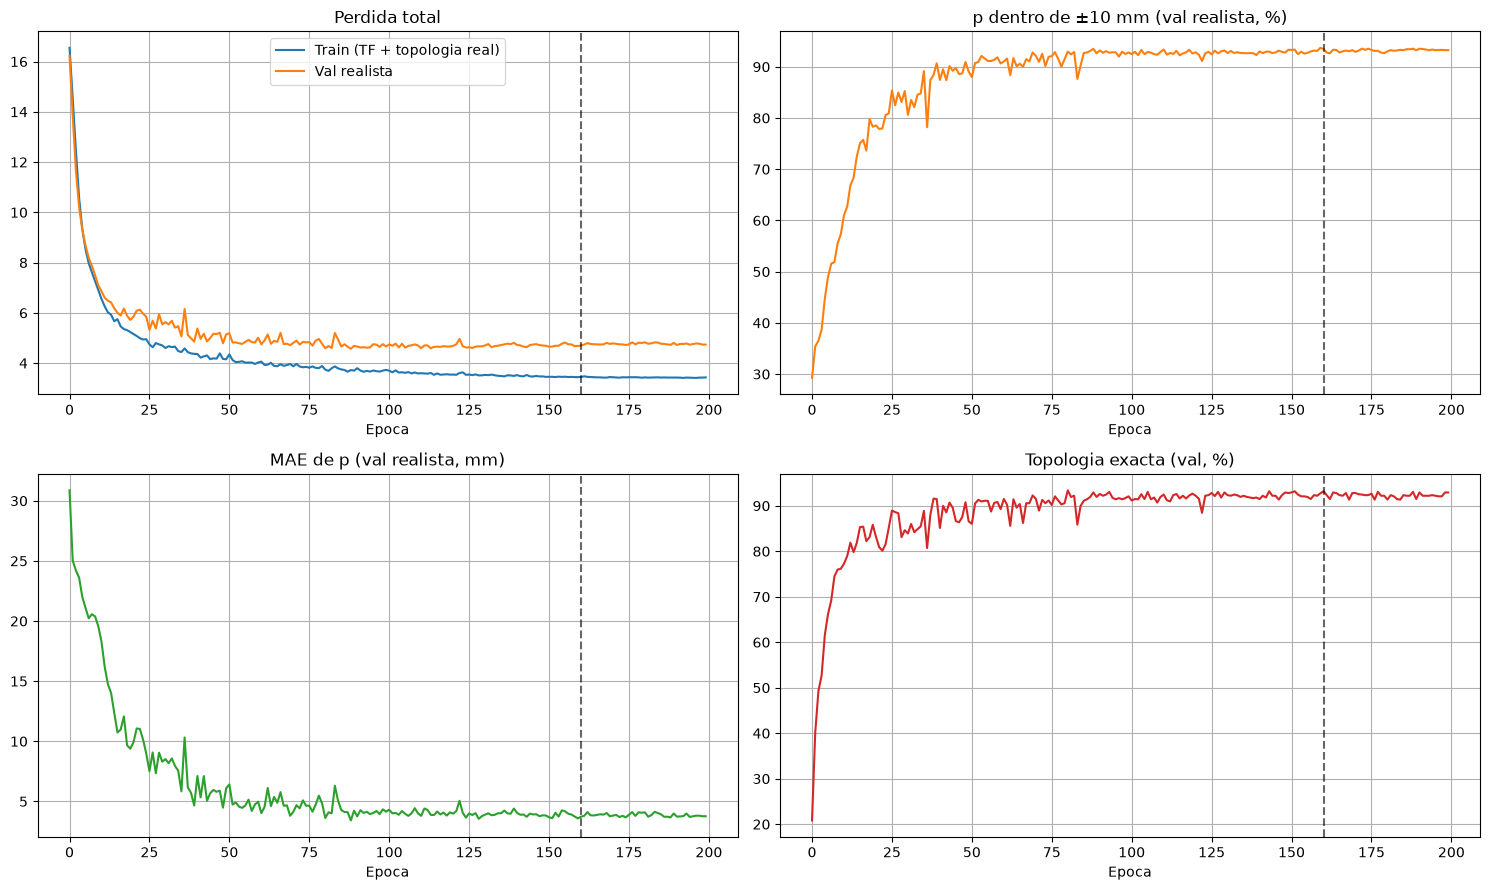

Mejor epoca: 161 | criterio: p_and_topology


In [ ]:
def curve(key, scale=1.0):
    return [scale * x.get(key, np.nan) for x in history["val_parts"]]

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
ax[0, 0].plot(history["train_loss"], label="Train (TF + topologia real)")
ax[0, 0].plot(history["val_loss"], label="Val realista")
ax[0, 0].set_title("Perdida total"); ax[0, 0].legend()
ax[0, 1].plot(curve("p_within_10", 100), color="tab:orange")
ax[0, 1].set_title("p dentro de ±10 mm (val realista, %)")
ax[1, 0].plot(curve("p_mae_mm"), color="tab:green")
ax[1, 0].set_title("MAE de p (val realista, mm)")
ax[1, 1].plot(curve("topology_exact", 100), color="tab:red")
ax[1, 1].set_title("Topologia exacta (val, %)")
for a in ax.ravel():
    a.axvline(history["best_epoch"] - 1, color="black", linestyle="--", alpha=0.6)
    a.set_xlabel("Epoca"); a.grid(True)
plt.tight_layout(); plt.show()
print("Mejor epoca:", history["best_epoch"], "| criterio:", history["select_metric"])

## 12. Predicción en test y comparación validación vs. test

La época se elige con validación, así que la validación está algo optimista. Si la diferencia con test es grande, hay sobreajuste a la selección (o un test pequeño: ~700 filas, diferencias de ±1,5 puntos son ruido).

In [ ]:
out_true, out_real, design_true, design_real = predict_designs(model, test_loader)
display(design_real.head())

_, _, val_true, val_real = predict_designs(model, val_loader)
display(pd.DataFrame({"validacion": kpis(df_val, val_real, val_true),
                      "test": kpis(df_test, design_real, design_true)}).round(2))

,g,e,d,Bp,tp,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12,tws,ts,tbs,tst,Bolt,standard,SlipCritical,n_alma,n_cantonera,Hole,num_filas_tornillos,tiene_cantonera
0,125.0,40.0,59.760933,230.0,20.0,135.0,215.0,135.0,60.0,155.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,10.0,0.0,20,AISC-360-05/10,NO,2,2,22,6,True
1,110.0,40.0,43.107105,194.0,20.0,90.0,200.0,90.0,140.0,105.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,10.0,0.0,20,AISC-360-05/10,NO,2,2,22,6,True
2,110.0,40.0,41.995190,278.0,20.0,90.0,55.0,95.0,125.0,55.0,110.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,12.0,12.0,0.0,20,AISC-360-05/10,NO,3,2,22,7,True
3,115.0,40.0,39.326599,236.0,25.0,90.0,55.0,75.0,150.0,55.0,110.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,12.0,10.0,15.0,20,AISC-360-05/10,NO,3,2,22,7,True
4,125.0,40.0,59.760933,230.0,20.0,135.0,215.0,135.0,60.0,155.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,10.0,0.0,20,AISC-360-05/10,NO,2,2,22,6,True


,validacion,test
p_MAE_mm,2.92,2.46
p_pct_10mm,95.44,95.86
p_pct_>20mm,3.82,3.13
p99_mm,87.05,70.00
topologia_exacta_%,94.87,95.61
p_pct_10mm_topologia_real,96.89,96.97


## 13. Métricas de p

- **topología real** = lo que da la parte de p cuando la estructura está bien (techo);
- **inferencia realista** = lo que verá el usuario final;
- **colas** (`pct_>20mm`, `p95`, `p99`): donde está el problema de fiabilidad.

In [ ]:
summary = pd.DataFrame({
    "topologia real": resumen_p(df_test, design_true),
    "inferencia realista": resumen_p(df_test, design_real),
})
display(summary.round(2))

,topologia real,inferencia realista
N_separaciones,3071.00,3071.00
MAE_mm,1.63,2.46
RMSE_mm,10.59,14.19
mediana_abs_mm,0.00,0.00
pct_<=5mm,95.83,94.76
pct_<=10mm,96.97,95.86
pct_>20mm,2.02,3.13
p95_abs_mm,5.00,10.00
p99_abs_mm,46.50,70.00


In [ ]:
print("=== TOPOLOGIA REAL ===")
real_df, pred_df = preparar_para_evaluar(df_test, design_true)
metrics_true = evaluar_predicciones(real_df, pred_df)

print("\n=== INFERENCIA REALISTA ===")
real_df, pred_df = preparar_para_evaluar(df_test, design_real)
metrics_realistic = evaluar_predicciones(real_df, pred_df)

=== TOPOLOGIA REAL ===
Variable   N  MAE_mm  RMSE_mm     R2  pct_5mm  pct_10mm
       g 661   1.800    4.098  0.936   92.436    98.033
       e 661   0.197    1.695  0.901   99.697    99.697
       d 661   0.850    1.548  0.968   97.731    99.849
      Bp 661   3.123    4.880  0.992   85.023    96.520
      tp 661   0.434    1.862  0.895   99.092    99.546
      p1 661   0.513    3.046  0.984   96.974    99.092
      p2 661   1.737    9.538  0.925   94.856    95.915
      p3 651   1.459    7.926  0.962   95.699    96.313
      p4 476   2.154   13.898  0.884   96.639    96.639
      p5 294   2.723   14.157  0.812   93.197    96.259
      p6 166   3.072   17.689  0.739   95.783    95.783
      p7  72   0.486    2.282  0.993   97.222    98.611
      p8  39   4.744   29.624 -0.004   97.436    97.436
      p9  27   0.185    0.962  0.999  100.000   100.000
     p10  18   0.000    0.000  1.000  100.000   100.000
     p11   3   0.000    0.000    NaN  100.000   100.000
     p12   3   0.000    0

### Otras salidas categóricas

El reference solo evalúa geometría; aquí se añade el acierto de las clasificaciones (`standard`, `Bolt`, `SlipCritical`). Recuerda que `standard` es casi trivial porque `Normativas` se copió de él.

In [ ]:
cls_rows = []
for col in ["standard", "Bolt", "SlipCritical"]:
    real_c = df_test[col].astype(str).str.replace("M", "", regex=False).to_numpy()
    pred_c = design_real[col].astype(str).to_numpy()
    cls_rows.append({"variable": col, "acierto_%": 100 * np.mean(real_c == pred_c)})
for col in ["tws", "ts", "tbs", "tst"]:
    real_pres = df_test[col].fillna(0).to_numpy() > 0
    pred_pres = design_real[col].to_numpy() > 0
    cls_rows.append({"variable": f"{col} (presencia)", "acierto_%": 100 * np.mean(real_pres == pred_pres)})
classification_metrics = pd.DataFrame(cls_rows)
display(classification_metrics.round(2))

,variable,acierto_%
0,standard,100.00
1,Bolt,97.13
2,SlipCritical,98.64
3,tws (presencia),95.31
4,ts (presencia),100.00
5,tbs (presencia),98.49
6,tst (presencia),98.94


## 14. Topología: exactitud, confusión y contribución al error de p

In [ ]:
print("Exactitud de estructura:")
structure = evaluar_estructura(df_test, design_real)

real_na = df_test["n_alma"].astype(int).reset_index(drop=True)
real_nc = df_test["n_cantonera"].astype(int).reset_index(drop=True)
print("\nConfusion n_alma")
display(pd.crosstab(real_na.rename("real"), design_real["n_alma"].astype(int).rename("pred")))
print("Confusion n_cantonera")
display(pd.crosstab(real_nc.rename("real"), design_real["n_cantonera"].astype(int).rename("pred")))

print("Contribucion de la topologia al error de p")
topology_contribution = contribucion_error_topologia(df_test, design_real)
display(topology_contribution.round(2))

Exactitud de estructura:
n_alma_exacto         0.983359
n_cantonera_exacto    0.963691
ambos_exactos         0.956127

Confusion n_alma


pred,1,2,3,4,5,6
real,,,,,,
1,10,0,0,0,0,0
2,0,371,4,0,0,0
3,0,3,210,0,0,0
4,0,0,4,33,0,0
5,0,0,0,0,23,0
6,0,0,0,0,0,3


Confusion n_cantonera


pred,0,1,2,3,4,5
real,,,,,,
0,290,4,6,3,0,0
1,1,87,0,0,0,0
2,3,3,188,4,0,0
3,0,0,0,45,0,0
4,0,0,0,0,24,0
5,0,0,0,0,0,3


Contribucion de la topologia al error de p


,grupo,n_conexiones,n_separaciones,MAE_mm,pct_<=10mm,pct_<=20mm,pct_del_error_total
0,topologia correcta,632,2939,0.59,98.64,99.12,22.83
1,topologia incorrecta,29,132,44.08,34.09,46.97,77.17


## 15. Sesgo, posición acumulada y transiciones

In [ ]:
bias_table = evaluar_sesgo_p(df_test, design_real)
print("Sesgo por p (inferencia realista)")
display(bias_table.round(2))

position_table = evaluar_acumulado_y(df_test, design_real, incluir_e=True)
print("Error de posicion acumulada absoluta (incluye e)")
display(position_table.round(2))

transition_summary, transition_detail = evaluar_por_transicion(df_test, design_real)
print("Por transicion (peores primero)")
display(transition_summary.round(2))

Sesgo por p (inferencia realista)


,Variable,N,MAE_mm,sesgo_mm,subestimadas_pct,subestimadas_mas_10_pct
0,p1,661,0.51,-0.06,2.72,0.61
1,p2,661,2.39,-0.44,3.18,2.42
2,p3,651,2.85,1.66,2.92,1.84
3,p4,476,2.92,-1.23,3.99,2.94
4,p5,294,4.21,-0.51,4.42,3.06
5,p6,166,5.18,-4.78,6.63,5.42
6,p7,72,1.25,0.83,2.78,0.00
7,p8,39,4.74,-4.74,2.56,2.56
8,p9,27,0.19,0.19,0.00,0.00
9,p10,18,0.00,0.00,0.00,0.00


Error de posicion acumulada absoluta (incluye e)


,Y_hasta,N,MAE_acumulado_mm,pct_10mm,pct_20mm
0,p1,661,0.71,98.03,99.39
1,p2,661,2.86,95.01,96.22
2,p3,651,3.42,94.47,95.24
3,p4,476,5.06,92.65,93.28
4,p5,294,6.94,90.48,91.50
5,p6,166,8.49,90.96,92.77
6,p7,72,6.39,91.67,93.06
7,p8,39,4.74,94.87,94.87
8,p9,27,0.37,100.00,100.00
9,p10,18,0.00,100.00,100.00


Por transicion (peores primero)


,transicion,N,MAE_mm,sesgo_mm,dentro_10_pct,subestimadas_mas_10_pct
15,viga centro superior__viga centro inferior,40,13.75,11.50,85.00,5.00
7,cantonera primero__cantonera centro,45,6.78,-5.98,91.11,8.89
13,viga centro inferior__viga inferior,63,1.90,0.48,92.06,3.17
22,viga inferior__inferior,293,2.70,0.85,93.52,1.37
24,viga primero__viga centro superior,63,1.35,-0.56,93.65,4.76
23,viga primero__viga centro,213,2.70,1.06,93.90,2.35
19,viga centro__viga inferior,213,2.49,1.13,93.90,1.88
21,viga inferior__cantonera primero,270,4.02,-1.14,94.07,4.07
9,cantonera primero__cantonera inferior,198,3.35,0.91,94.95,2.02
6,cantonera inferior__inferior,270,4.85,-3.94,95.19,4.07


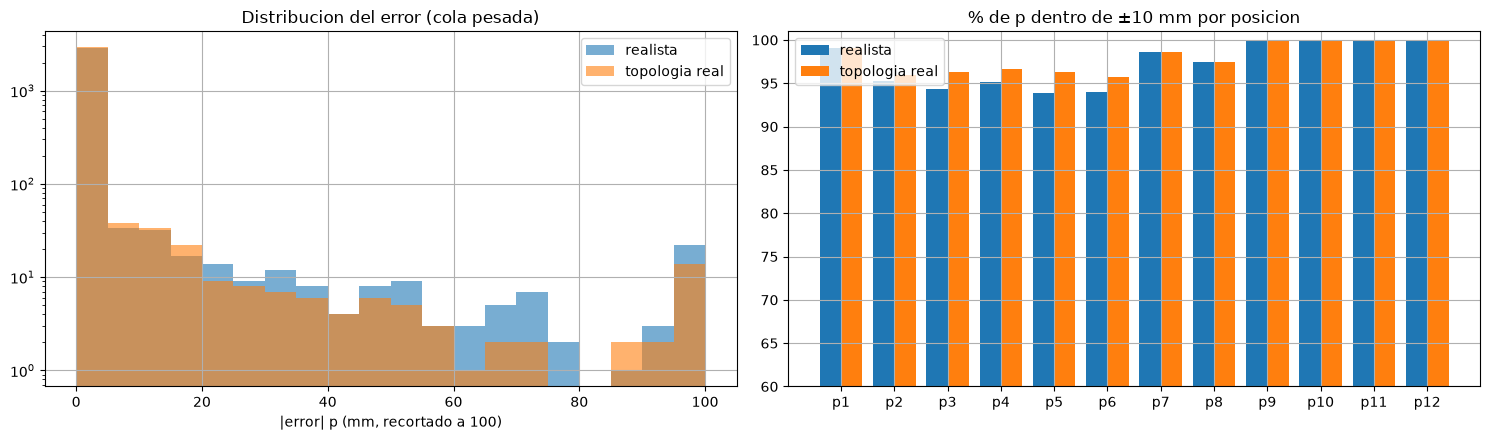

In [ ]:
real_matrix = df_test[P_COLUMNS].fillna(0.0).to_numpy(float)
pred_matrix_r = design_real[P_COLUMNS].to_numpy(float)
pred_matrix_t = design_true[P_COLUMNS].to_numpy(float)
active_m = real_matrix > 0

err_r = np.abs(pred_matrix_r - real_matrix)[active_m]
err_t = np.abs(pred_matrix_t - real_matrix)[active_m]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
bins = np.arange(0, 105, 5)
ax[0].hist(np.clip(err_r, 0, 100), bins=bins, alpha=0.6, label="realista")
ax[0].hist(np.clip(err_t, 0, 100), bins=bins, alpha=0.6, label="topologia real")
ax[0].set_yscale("log"); ax[0].set_xlabel("|error| p (mm, recortado a 100)"); ax[0].set_title("Distribucion del error (cola pesada)")
ax[0].legend(); ax[0].grid(True)

def pct10(pred):
    return [100 * np.mean(np.abs(pred[active_m[:, j], j] - real_matrix[active_m[:, j], j]) <= 10)
            if active_m[:, j].any() else np.nan for j in range(N_Y)]

x = np.arange(N_Y)
ax[1].bar(x - 0.2, pct10(pred_matrix_r), 0.4, label="realista")
ax[1].bar(x + 0.2, pct10(pred_matrix_t), 0.4, label="topologia real")
ax[1].set_xticks(x); ax[1].set_xticklabels(P_COLUMNS); ax[1].set_ylim(60, 101)
ax[1].set_title("% de p dentro de ±10 mm por posicion"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()

## 16. Casos extremos

In [ ]:
abs_err = np.abs(pred_matrix_r - real_matrix)
abs_err[~active_m] = np.nan
extreme = pd.DataFrame({
    "indice_test": np.arange(len(df_test)),
    "UNICODE": df_test["UNICODE"].to_numpy() if "UNICODE" in df_test else np.arange(len(df_test)),
    "BEAM": df_test["BEAM"].to_numpy(),
    "COLUMN": df_test["COLUMN"].to_numpy(),
    "max_error_mm": np.nanmax(abs_err, axis=1),
    "mean_error_mm": np.nanmean(abs_err, axis=1),
    "peor_p": np.nanargmax(abs_err, axis=1) + 1,
    "n_alma_real": df_test["n_alma"].astype(int).to_numpy(),
    "n_alma_pred": design_real["n_alma"].astype(int).to_numpy(),
    "n_cantonera_real": df_test["n_cantonera"].astype(int).to_numpy(),
    "n_cantonera_pred": design_real["n_cantonera"].astype(int).to_numpy(),
})
extreme["topologia_correcta"] = (
    (extreme.n_alma_real == extreme.n_alma_pred) & (extreme.n_cantonera_real == extreme.n_cantonera_pred)
)
extreme = extreme.sort_values("max_error_mm", ascending=False)
display(extreme.head(25).round(2))
print("Entre las 40 peores conexiones, con topologia incorrecta:", int((~extreme.head(40).topologia_correcta).sum()))

,indice_test,UNICODE,BEAM,COLUMN,max_error_mm,mean_error_mm,peor_p,n_alma_real,n_alma_pred,n_cantonera_real,n_cantonera_pred,topologia_correcta
6,6,JBR6009,IPE450,HEA500,245.8,99.22,2,2,3,2,3,False
644,644,MOE6345,HEB600,HEB450,185.0,85.00,8,4,3,3,3,False
493,493,MLE6399,IPE360,HI920-30-65*350,140.0,55.00,2,2,3,0,0,False
655,655,MSE6007,HEA500,HEB500,140.0,43.00,3,4,3,0,3,False
591,591,MOE6016,HEA450,HEA400,135.0,60.00,4,3,3,2,3,False
659,659,MSE6040,HEA500,HEB700,135.0,43.00,3,4,3,0,3,False
635,635,MOE6298,HEB260,HEA320,135.0,51.00,5,2,2,2,1,False
70,70,MHE0371,IPE360,HEB500,130.0,55.83,6,3,3,2,0,False
651,651,MOE6392,HEA300,HEM600,130.0,41.67,6,3,3,2,0,False
467,467,MLE6190,HEA260,HEB300,125.0,68.33,6,3,2,2,0,False


Entre las 40 peores conexiones, con topologia incorrecta: 27


## 17. Confianza de las p (solo v4) y triaje

`prob_dentro_10` es la masa de probabilidad a ≤ ±10 mm de la moda. Si está bien calibrada, sirve para **marcar conexiones que un ingeniero debería revisar**.

In [ ]:
if CFG["model"] == "v4":
    p_mode_prob, p_prob10 = p_confidence(out_real["p_logits"])
    print("Calibracion (tramo de confianza predicha vs acierto real <=10 mm)")
    display(calibracion_confianza_p(df_test, design_real, p_prob10).round(2))

    k_pred = design_real["n_alma"].astype(int).to_numpy() + design_real["n_cantonera"].astype(int).to_numpy() + 1
    active_pred = np.arange(N_Y)[None, :] < k_pred[:, None]
    conn_conf = np.where(active_pred, p_prob10, 1.0).min(axis=1)

    topo_ok = ((df_test["n_alma"].astype(int).to_numpy() == design_real["n_alma"].astype(int).to_numpy())
               & (df_test["n_cantonera"].astype(int).to_numpy() == design_real["n_cantonera"].astype(int).to_numpy()))
    all_p_ok = np.all((np.abs(pred_matrix_r - real_matrix) <= 10) | ~active_m, axis=1) & topo_ok

    rows = []
    for thr in [0.5, 0.7, 0.85, 0.95]:
        flagged = conn_conf < thr
        rows.append({
            "umbral_confianza": thr,
            "% conexiones marcadas para revision": 100 * flagged.mean(),
            "% correctas entre las NO marcadas": 100 * all_p_ok[~flagged].mean() if (~flagged).any() else np.nan,
            "% correctas global": 100 * all_p_ok.mean(),
        })
    print("Triaje: conexion correcta = topologia correcta y todas las p dentro de ±10 mm")
    display(pd.DataFrame(rows).round(1))
else:
    print("Modelo v3: no hay distribucion por p, se omite la confianza.")

Modelo v3: no hay distribucion por p, se omite la confianza.


## 18. Comprobación con el adapter de producción

Pasa las features de test por `adapter.predict` (el mismo camino que usará el servidor, sin teacher forcing) y comprueba que coincide con la inferencia realista de este notebook. Detecta discrepancias entre el decodificado del notebook y `core/postprocess.py`.

In [ ]:
try:
    model.eval()
    bundle = {"model": model, "pre": pre, "device": DEVICE}
    prod = adapter.predict(df_test[CATEGORICAL_FEATURES + NUMERIC_FEATURES], bundle)

    checks = {
        "n_alma": np.array_equal(prod["n_alma"].astype(int), design_real["n_alma"].astype(int)),
        "n_cantonera": np.array_equal(prod["n_cantonera"].astype(int), design_real["n_cantonera"].astype(int)),
        "Bolt": np.array_equal(prod["Bolt"].astype(int), design_real["Bolt"].astype(int)),
        "standard": np.array_equal(prod["standard"].astype(str), design_real["standard"].astype(str)),
        "p1..p12": np.allclose(prod[P_COLUMNS].to_numpy(float), design_real[P_COLUMNS].to_numpy(float)),
        "g,e,d,Bp,tp": np.allclose(prod[REGRESSION_ALWAYS].to_numpy(float), design_real[REGRESSION_ALWAYS].to_numpy(float)),
        "tws,ts,tbs,tst": np.allclose(prod[STIFFENER_COLUMNS].to_numpy(float), design_real[STIFFENER_COLUMNS].to_numpy(float)),
    }
    print(pd.Series(checks).to_string())
except Exception as exc:
    print("No se pudo ejecutar la comprobacion con el adapter:", type(exc).__name__, exc)

n_alma            True
n_cantonera       True
Bolt              True
standard          True
p1..p12           True
g,e,d,Bp,tp       True
tws,ts,tbs,tst    True


## 19. Guardado de artefactos

`weights.pt` + `preprocessor.joblib` son los dos ficheros que carga `adapter.load()`; se guardan también como `model_final.pt`. Se guarda además el dataset ya completado (con `b/tf/tw` y `Normativas`) para no repetir el paso 3.

In [ ]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "cfg": CFG,
    "best_epoch": history["best_epoch"],
    "n_p_bins": N_BINS,
    "p_bin_step_mm": Y_GRID_STEP,
    "cat_cardinalities": pre.cat_cardinalities,
    "numeric_features": list(NUMERIC_FEATURES),
    "n_standard_classes": pre.n_standard_classes,
    "hidden_dim": HIDDEN_DIM, "num_blocks": NUM_BLOCKS, "dropout": DROPOUT, "gru_hidden_dim": GRU_HIDDEN_DIM,
    "p_mean_mm": pre.masked_mean[:N_Y], "p_std_mm": pre.masked_std[:N_Y],
}
torch.save(checkpoint, OUTPUT_DIR / "model_final.pt")
torch.save(checkpoint, OUTPUT_DIR / "weights.pt")            # nombre que espera adapter.load()
joblib.dump(pre, OUTPUT_DIR / "preprocessor.joblib")
joblib.dump(history, OUTPUT_DIR / "history.joblib")
design_real.to_parquet(OUTPUT_DIR / "test_predictions.parquet", index=False)
df.to_parquet(OUTPUT_DIR / "datos_modelo_completo.parquet", index=False)

with pd.ExcelWriter(OUTPUT_DIR / "metricas.xlsx", engine="openpyxl") as writer:
    summary.to_excel(writer, sheet_name="resumen_p")
    metrics_true.to_excel(writer, sheet_name="topologia_real", index=False)
    metrics_realistic.to_excel(writer, sheet_name="inferencia_realista", index=False)
    classification_metrics.to_excel(writer, sheet_name="clasificaciones", index=False)
    topology_contribution.to_excel(writer, sheet_name="contribucion_topologia", index=False)
    bias_table.to_excel(writer, sheet_name="sesgo_p", index=False)
    position_table.to_excel(writer, sheet_name="posicion_acumulada", index=False)
    transition_summary.to_excel(writer, sheet_name="transiciones", index=False)
    extreme.to_excel(writer, sheet_name="casos_extremos", index=False)
print("Artefactos en:", OUTPUT_DIR.resolve())

Artefactos en: C:\Users\aarbona\OneDrive - Tecnicas Reunidas, S.A\Documentos\proyecto_uniones\V12\artifacts_v4


## 20. Ablación escalonada con varias semillas (opcional)

Cada paso cambia **una cosa** respecto al anterior (A→E). Activa `RUN_ABLATION = True` en la sección 1. Con 3 semillas son 15 entrenamientos; reduce `EPOCHS` para una comparación rápida. Las semillas cambian inicialización y orden de lotes, no la partición.

| | modelo | pesos de clase | topología | selección de época |
|---|---|---|---|---|
| A | v3 original | sí | independiente | `val_loss` |
| B | v3 | **no** | independiente | `val_loss` |
| C | **v4 (p discreta)** | no | independiente | `val_loss` |
| D | v4 | no | **conjunta** | `val_loss` |
| E | v4 | no | conjunta | **`p_and_topology`** |

In [ ]:
ABLATION_CONFIGS = {
    "A_v3_original": {**DEFAULT_CFG, "model": "v3", "joint_topology": False, "class_weights": True, "select_metric": "val_loss"},
    "B_v3_sin_pesos": {**DEFAULT_CFG, "model": "v3", "joint_topology": False, "class_weights": False, "select_metric": "val_loss"},
    "C_v4_p_discreta": {**DEFAULT_CFG, "model": "v4", "joint_topology": False, "class_weights": False, "select_metric": "val_loss"},
    "D_v4_topologia_conjunta": {**DEFAULT_CFG, "model": "v4", "joint_topology": True, "class_weights": False, "select_metric": "val_loss"},
    "E_v4_seleccion_por_p": {**DEFAULT_CFG, "model": "v4", "joint_topology": True, "class_weights": False, "select_metric": "p_and_topology"},
}

if RUN_ABLATION:
    ablation_rows = []
    for name, cfg in ABLATION_CONFIGS.items():
        for seed in ABLATION_SEEDS:
            set_seed(seed)
            m, crit = build_experiment(cfg)
            fit(m, train_loader, val_loader, crit, DEVICE, epochs=EPOCHS, lr=LEARNING_RATE,
                weight_decay=WEIGHT_DECAY, checkpoint_path=None, log_every=10**9,
                select_metric=cfg["select_metric"], verbose=False)
            _, _, d_true, d_real = predict_designs(m, test_loader)
            ablation_rows.append({"config": name, "seed": seed, **kpis(df_test, d_real, d_true)})
            print(f"{name} seed={seed}: p<=10mm {ablation_rows[-1]['p_pct_10mm']:.1f}% | "
                  f"topologia {ablation_rows[-1]['topologia_exacta_%']:.1f}%")
    ablation = pd.DataFrame(ablation_rows)
    agg = ablation.groupby("config").agg(["mean", "std"]).drop(columns="seed")
    display(agg.round(2))
    ablation.to_csv(OUTPUT_DIR / "ablacion.csv", index=False)
else:
    print("RUN_ABLATION=False: omitida.")

RUN_ABLATION=False: omitida.
